In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import pybamm
import pickle

In [2]:
def OCV(sto):
    return 5.5-sto

def electrolyte_diffusivity_Landesfeind2019_EC_EMC(c_e, T):
    c=c_e/1000
    D_c_e = 1010*2.71828**(1.01*c)*2.71828**((-1560)/T)*2.71828**((-487)/T*c)*10**(-10)

    return D_c_e

def electrolyte_conductivity_Landesfeind2019_EC_EMC(c_e, T):
    c=c_e/1000
    #mol/dm3, K, to mS/cm
    sigma_e = (
        0.521 * (1 + (T - 228)) * 
        c * 
        (1 + (-1.06*c**0.5) + (0.353*(1 - 0.00359*2.71828**(1000/T))*c))/
        (1 + c**4 * (0.00148*2.71828**(1000/T)))
    )
    return sigma_e/10 # mS/cm -> S/m

def TDF_Landesfeind2019_EC_EMC(c_e, T):
    c=c_e/1000
    TDF = (
        25.7 - 45.1*c - 0.177*T + 1.94*c**2 + (0.295)*c*T + (0.000308)*T**2 + 0.259*c**3 + (-0.00946)*c**2*T - 0.000454*c*T**2
    )
    return TDF

def Cation_transference_number_Landesfeind2019_EC_EMC(c_e, T):
    c=c_e/1000
    C_t_n = (
        -12.8 - 6.12*c + 0.0821*T + 0.904*c**2 + (0.0318)*c*T + (-0.000127)*T**2 + 0.0175*c**3 + (-0.00312)*c**2*T - 0.0000396*c*T**2
    )
    return C_t_n

values = {
        "chemistry": "lithium_ion",

        "Negative electrode Bruggeman coefficient (electrode)": 0,
        "Negative electrode charge transfer coefficient": 0.5,
        "Positive electrode Bruggeman coefficient (electrode)": 0,
        "Positive electrode charge transfer coefficient": 0.5,
        "Negative electrode OCP entropic change [V.K-1]": 0.0,
        "Positive electrode OCP entropic change [V.K-1]": 0.0,
        "Reference temperature [K]": 298.15,
        "Initial temperature [K]": 298.15,
        "Ambient temperature [K]": 273.15+25,
        "Number of electrodes connected in parallel to make a cell": 1.0,
        "Number of cells connected in series to make a battery": 1.0,
        "Lower voltage cut-off [V]": -1.5,
        "Upper voltage cut-off [V]": 50,
        "Open-circuit voltage at 0% SOC [V]": -1,
        "Open-circuit voltage at 100% SOC [V]": 1,
        "Negative current collector thickness [m]": 1.0e-05,
        "Positive current collector thickness [m]": 1.5e-05,
        "Electrode height [m]": 0.01,
        "Electrode width [m]": 0.01,
        "Nominal cell capacity [A.h]": 0.0018/6.5,
        "Current function [A]": 0.0018/6.5,
        "Contact resistance [Ohm]": 0,

        # electrode, separator
        "Negative electrode thickness [m]": 9e-06,
        "Positive electrode thickness [m]": 9e-06,
        "Separator thickness [m]": 50e-06,
        "Negative electrode conductivity [S.m-1]": 100.0,
        "Positive electrode conductivity [S.m-1]": 100.0,
        "Maximum concentration in negative electrode [mol.m-3]": 49570.4,
        "Maximum concentration in positive electrode [mol.m-3]": 49570.4,
        "Negative particle diffusivity [m2.s-1]": 1e-14,
        "Positive particle diffusivity [m2.s-1]": 1e-14,
        "Negative electrode OCP [V]": OCV,
        "Positive electrode OCP [V]": OCV,
        "Negative electrode porosity": 0.72549,
        "Positive electrode porosity": 0.72549,
        "Separator porosity": 0.55,
        "Negative electrode active material volume fraction": 0.84745917*(1-0.72549),
        "Positive electrode active material volume fraction": 0.84745917*(1-0.72549),
        "Negative particle radius [m]": 4.5e-06,    #surface area 0.0014 m2
        "Positive particle radius [m]": 4.5e-06,    #surface area 0.0014 m2
        "Negative electrode Bruggeman coefficient (electrolyte)": 2.3,
        "Positive electrode Bruggeman coefficient (electrolyte)": 2.3, 
        "Separator Bruggeman coefficient (electrolyte)": 2.53,
        "Negative electrode double-layer capacity [F.m-2]": 1.0128,
        "Positive electrode double-layer capacity [F.m-2]": 1.0128,
        "Negative electrode exchange-current density [A.m-2]": 10.07,
        "Positive electrode exchange-current density [A.m-2]": 10.07,
        "Negative electrode density [kg.m-3]": 2614.8,
        "Positive electrode density [kg.m-3]": 2614.8,
        "Separator density [kg.m-3]": 200.0,
        # electrolyte
        "Initial concentration in electrolyte [mol.m-3]": 1000.0,
        "Cation transference number": Cation_transference_number_Landesfeind2019_EC_EMC,
        "Thermodynamic factor": TDF_Landesfeind2019_EC_EMC,
        "Electrolyte diffusivity [m2.s-1]": electrolyte_diffusivity_Landesfeind2019_EC_EMC,
        "Electrolyte conductivity [S.m-1]": electrolyte_conductivity_Landesfeind2019_EC_EMC,
        # experiment
        "Initial concentration in negative electrode [mol.m-3]": 49570.4/100*50,
        "Initial concentration in positive electrode [mol.m-3]": 49570.4/100*50,
    }

values["Exchange-current density for lithium metal electrode [A.m-2]"] = 1e3

param = pybamm.ParameterValues(values)
model = pybamm.lithium_ion.DFN(options={"surface form": "differential"})

var_pts = {
    "x_n": 1000,  # negative electrode
    "x_s": 1000,  # separator
    "x_p": 1000,  # positive electrode
    "r_n": 100,  # negative particle
    "r_p": 100,  # positive particle
}

In [3]:
L_n = model.param.n.L  # Negative electrode thickness [m]
L_s = model.param.s.L  # Separator thickness [m]
L_ref = L_n + L_s / 2  # Reference electrode position [m]
submesh_types = model.default_submesh_types
submesh_types["positive particle"] = pybamm.MeshGenerator(pybamm.Exponential1DSubMesh, submesh_params={"side": "right"})
model.insert_reference_electrode(L_ref)

In [4]:
AM_volume = param["Positive electrode thickness [m]"]*0.01*0.01*param["Positive electrode active material volume fraction"]
Q = AM_volume * param["Maximum concentration in positive electrode [mol.m-3]"] * 96485

R_electric = (1/param["Positive electrode conductivity [S.m-1]"] * param["Positive electrode thickness [m]"]/(0.01*0.01))

R_sep_elyte = 1/electrolyte_conductivity_Landesfeind2019_EC_EMC(1000,298)*(param["Separator thickness [m]"]/2)/(0.01*0.01)*param["Separator porosity"]**-param["Separator Bruggeman coefficient (electrolyte)"]
R_coat_elyte = (1/electrolyte_conductivity_Landesfeind2019_EC_EMC(1000,298)*param["Positive electrode thickness [m]"]/(0.01*0.01)*param["Positive electrode porosity"]**-param["Positive electrode Bruggeman coefficient (electrolyte)"])

R_CT = 8.314*298 / (1*96485* (AM_volume*3/param["Positive particle radius [m]"]) * param["Positive electrode exchange-current density [A.m-2]"])
sw = (electrolyte_diffusivity_Landesfeind2019_EC_EMC(1000,298)*96485**2*1000) / (2*8.314*298*TDF_Landesfeind2019_EC_EMC(1000, 298)*(1-Cation_transference_number_Landesfeind2019_EC_EMC(1000, 298))**2)
R_sep_elyte_diff = 1/sw*(param["Separator thickness [m]"]/2)/(0.01*0.01)*param["Separator porosity"]**-param["Separator Bruggeman coefficient (electrolyte)"]
R_coat_elyte_diff =1/sw*param["Positive electrode thickness [m]"]/(0.01*0.01)*param["Positive electrode porosity"]**-param["Positive electrode Bruggeman coefficient (electrolyte)"]

print(f"R_electric=\t{R_electric:.2e}\n", f"R_sep_elyte=\t{R_sep_elyte:.2f}\n", f"R_coat_elyte=\t{R_coat_elyte:.2f}\n", f"R_CT=\t\t{R_CT:.2f}\n", f"R_sep_elyte_diff={R_sep_elyte_diff:.2f}\n", f"R_coat_elyte_diff={R_coat_elyte_diff:.2f}\n")

R_electric=	9.00e-04
 R_sep_elyte=	1.25
 R_coat_elyte=	0.21
 R_CT=		18.27
 R_sep_elyte_diff=2.78
 R_coat_elyte_diff=0.46



In [5]:
print(f"Cell capcaity=\t{Q/3.6:.2f} mAh")

Cell capcaity=	0.28 mAh


In [ ]:
# Function that solves DFN and calculates D
def D_calc(D, dSOLdU, I, t):
    values["Initial concentration in positive electrode [mol.m-3]"] = 49570.4*0.50 # 50 %SOLi
    values["Positive particle diffusivity [m2.s-1]"] = 10**-D
    def OCV_with_variable_angle(sto):
        dU = 1/dSOLdU
        return 5 + dU*(0.5-sto)
    values["Positive electrode OCP [V]"] = OCV_with_variable_angle
    param = pybamm.ParameterValues(values)

    # Data is generated only up to t, as data after it isn't used, as dSOL/dU is constant, then also it doesn't influence correctness of it's calculation

    experiment = pybamm.Experiment(
        [f"Discharge at {I} A for {t} second"],
        period=f"{t/100} second"
    )

    sim = pybamm.Simulation(model, experiment=experiment, var_pts=var_pts, parameter_values=param, submesh_types=submesh_types)
    sol = sim.solve()

    U3E = sol["Positive electrode 3E potential [V]"].entries[-1]
    OCV = sol["Positive electrode bulk open-circuit potential [V]"].entries[-1]
    R_total = (U3E - OCV)/(-I)

    R_D = R_total - R_electric/3 - (R_sep_elyte + R_sep_elyte_diff) - R_CT - (R_coat_elyte + R_coat_elyte_diff)/3

    D_fit = (4.5e-6)**2 / (3*5*dSOLdU*Q*R_D)


    """print(f"R_D=\t{sol["Positive particle concentration overpotential [V]"].entries[-1]/-I:.5e} Ohm {(4.5e-6)**2 / (3*5*dSOLdU*Q*10**-D):.5e}")
    print(f"R_CT=\t{sol["X-averaged positive electrode reaction overpotential [V]"].entries[-1]/-I:.5e} Ohm {R_CT:.5e}")
    print(f"R_diff=\t{sol["X-averaged concentration overpotential [V]"].entries[-1]/-I/2:.5e} Ohm {R_sep_elyte_diff+R_coat_elyte_diff/3:.5e}")
    print(f"R_elyte=\t{sol["X-averaged electrolyte ohmic losses [V]"].entries[-1]/-I/2:.5e} Ohm {R_sep_elyte+R_coat_elyte/3:.5e}")
    print(f"R_electric=\t{sol["X-averaged positive electrode ohmic losses [V]"].entries[-1]/-I:.5e} Ohm {R_electric/3:.5e}")"""


    print(f"D = 1e-{D} m2/s, dSOL/dU = {dSOLdU} 1/V, Error = {D_fit/(10**-D)-1:.2%}")
    return D_fit

In [ ]:
# test
D_calc(11,1,0.28e-6,1e6)

D = 1e-11 m2/s, dSOL/dU = 1 1/V, Error = 7.34%


np.float64(1.0733852333716829e-11)

In [8]:
# analysed D and dSOL/dU
D_steps =       [11,    12,     13,     14,     15,     16,     17] #  
dSOLdU_steps =  [0.1,   0.2,    0.5,    1,      2,      5,      10] # 

In [ ]:
D_fit_1 = np.zeros([7,7])
Error_1 = np.zeros([7,7])

for i in range(7):
    for j in range(7):
        D_fit_1[i,j] = D_calc(D_steps[i],dSOLdU_steps[j],0.2e-6,1e6)
        Error_1[i,j] = D_fit_1[i,j]/(10**-D_steps[i])-1

D = 1e-11 m2/s, dSOL/dU = 0.1 1/V, Error = 2.74%
D = 1e-11 m2/s, dSOL/dU = 0.2 1/V, Error = 3.17%
D = 1e-11 m2/s, dSOL/dU = 0.5 1/V, Error = 4.67%
D = 1e-11 m2/s, dSOL/dU = 1 1/V, Error = 7.34%
D = 1e-11 m2/s, dSOL/dU = 2 1/V, Error = 13.11%
D = 1e-11 m2/s, dSOL/dU = 5 1/V, Error = 34.93%
D = 1e-11 m2/s, dSOL/dU = 10 1/V, Error = 98.87%
D = 1e-12 m2/s, dSOL/dU = 0.1 1/V, Error = 0.38%
D = 1e-12 m2/s, dSOL/dU = 0.2 1/V, Error = 0.36%
D = 1e-12 m2/s, dSOL/dU = 0.5 1/V, Error = 0.46%
D = 1e-12 m2/s, dSOL/dU = 1 1/V, Error = 0.69%
D = 1e-12 m2/s, dSOL/dU = 2 1/V, Error = 1.17%
D = 1e-12 m2/s, dSOL/dU = 5 1/V, Error = 2.65%
D = 1e-12 m2/s, dSOL/dU = 10 1/V, Error = 5.22%
D = 1e-13 m2/s, dSOL/dU = 0.1 1/V, Error = 0.15%
D = 1e-13 m2/s, dSOL/dU = 0.2 1/V, Error = 0.09%
D = 1e-13 m2/s, dSOL/dU = 0.5 1/V, Error = 0.06%
D = 1e-13 m2/s, dSOL/dU = 1 1/V, Error = 0.07%
D = 1e-13 m2/s, dSOL/dU = 2 1/V, Error = 0.11%
D = 1e-13 m2/s, dSOL/dU = 5 1/V, Error = 0.25%
D = 1e-13 m2/s, dSOL/dU = 10 1/V, Err

In [ ]:
"""
# code for results saving
with open('data_1.pickle', 'wb') as handle:
    pickle.dump([D_fit_1,Error_1], handle, protocol=pickle.HIGHEST_PROTOCOL)"""

In [9]:
# code for results loading
with open('data_1.pickle', 'rb') as handle:
    [D_fit_1,Error_1] = pickle.load(handle)

In [ ]:
# export for comparison error plot
D_export = []
for i in range(7):
    for j in range(7):
        D_export.append(D_fit_1[i,j])
np.savetxt('NewMethod.txt', D_export, delimiter=',')

In [11]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams["mathtext.default"] = 'regular'
#plt.rcParams["axes.grid"] = False
def error_plot(name,error1, comment):
    fig, ax = plt.subplots(1,1,figsize=[5,5],dpi=600)

    ax.imshow(error1*100, cmap="jet",vmin=-50,vmax=50)
    ax.set_xlabel("dSOL/dU [1/V]")
    ax.set_title("$ D_{Calc.}\\ \% error\\ $"+comment) #, {np.sum(np.abs(error3*100)<50):.0f} under 50% 
    ax.set_xticks([0,1,2,3,4,5,6])
    ax.set_xticklabels(dSOLdU_steps)
    ax.set_yticks([0,1,2,3,4,5,6])
    ax.set_yticklabels(-np.array(D_steps))
    ax.set_ylabel("$log\u2081\u2080(D_{NMC}\\ [m\u00B2/s])$")

    for i in range(len(D_steps)):
        for j in range(len(dSOLdU_steps)):
            if (error1[i, j]*100 >-20) and (error1[i, j]*100 <26): color='k' 
            else: color='w'
            text = ax.text(j, i, f"{error1[i, j]*100:.0f}",
                        ha="center", va="center", color=color)

    plt.savefig(name+'.svg', dpi=600, bbox_inches='tight')
    #plt.savefig(name+'.svg', dpi=600, bbox_inches='tight')
    plt.show()

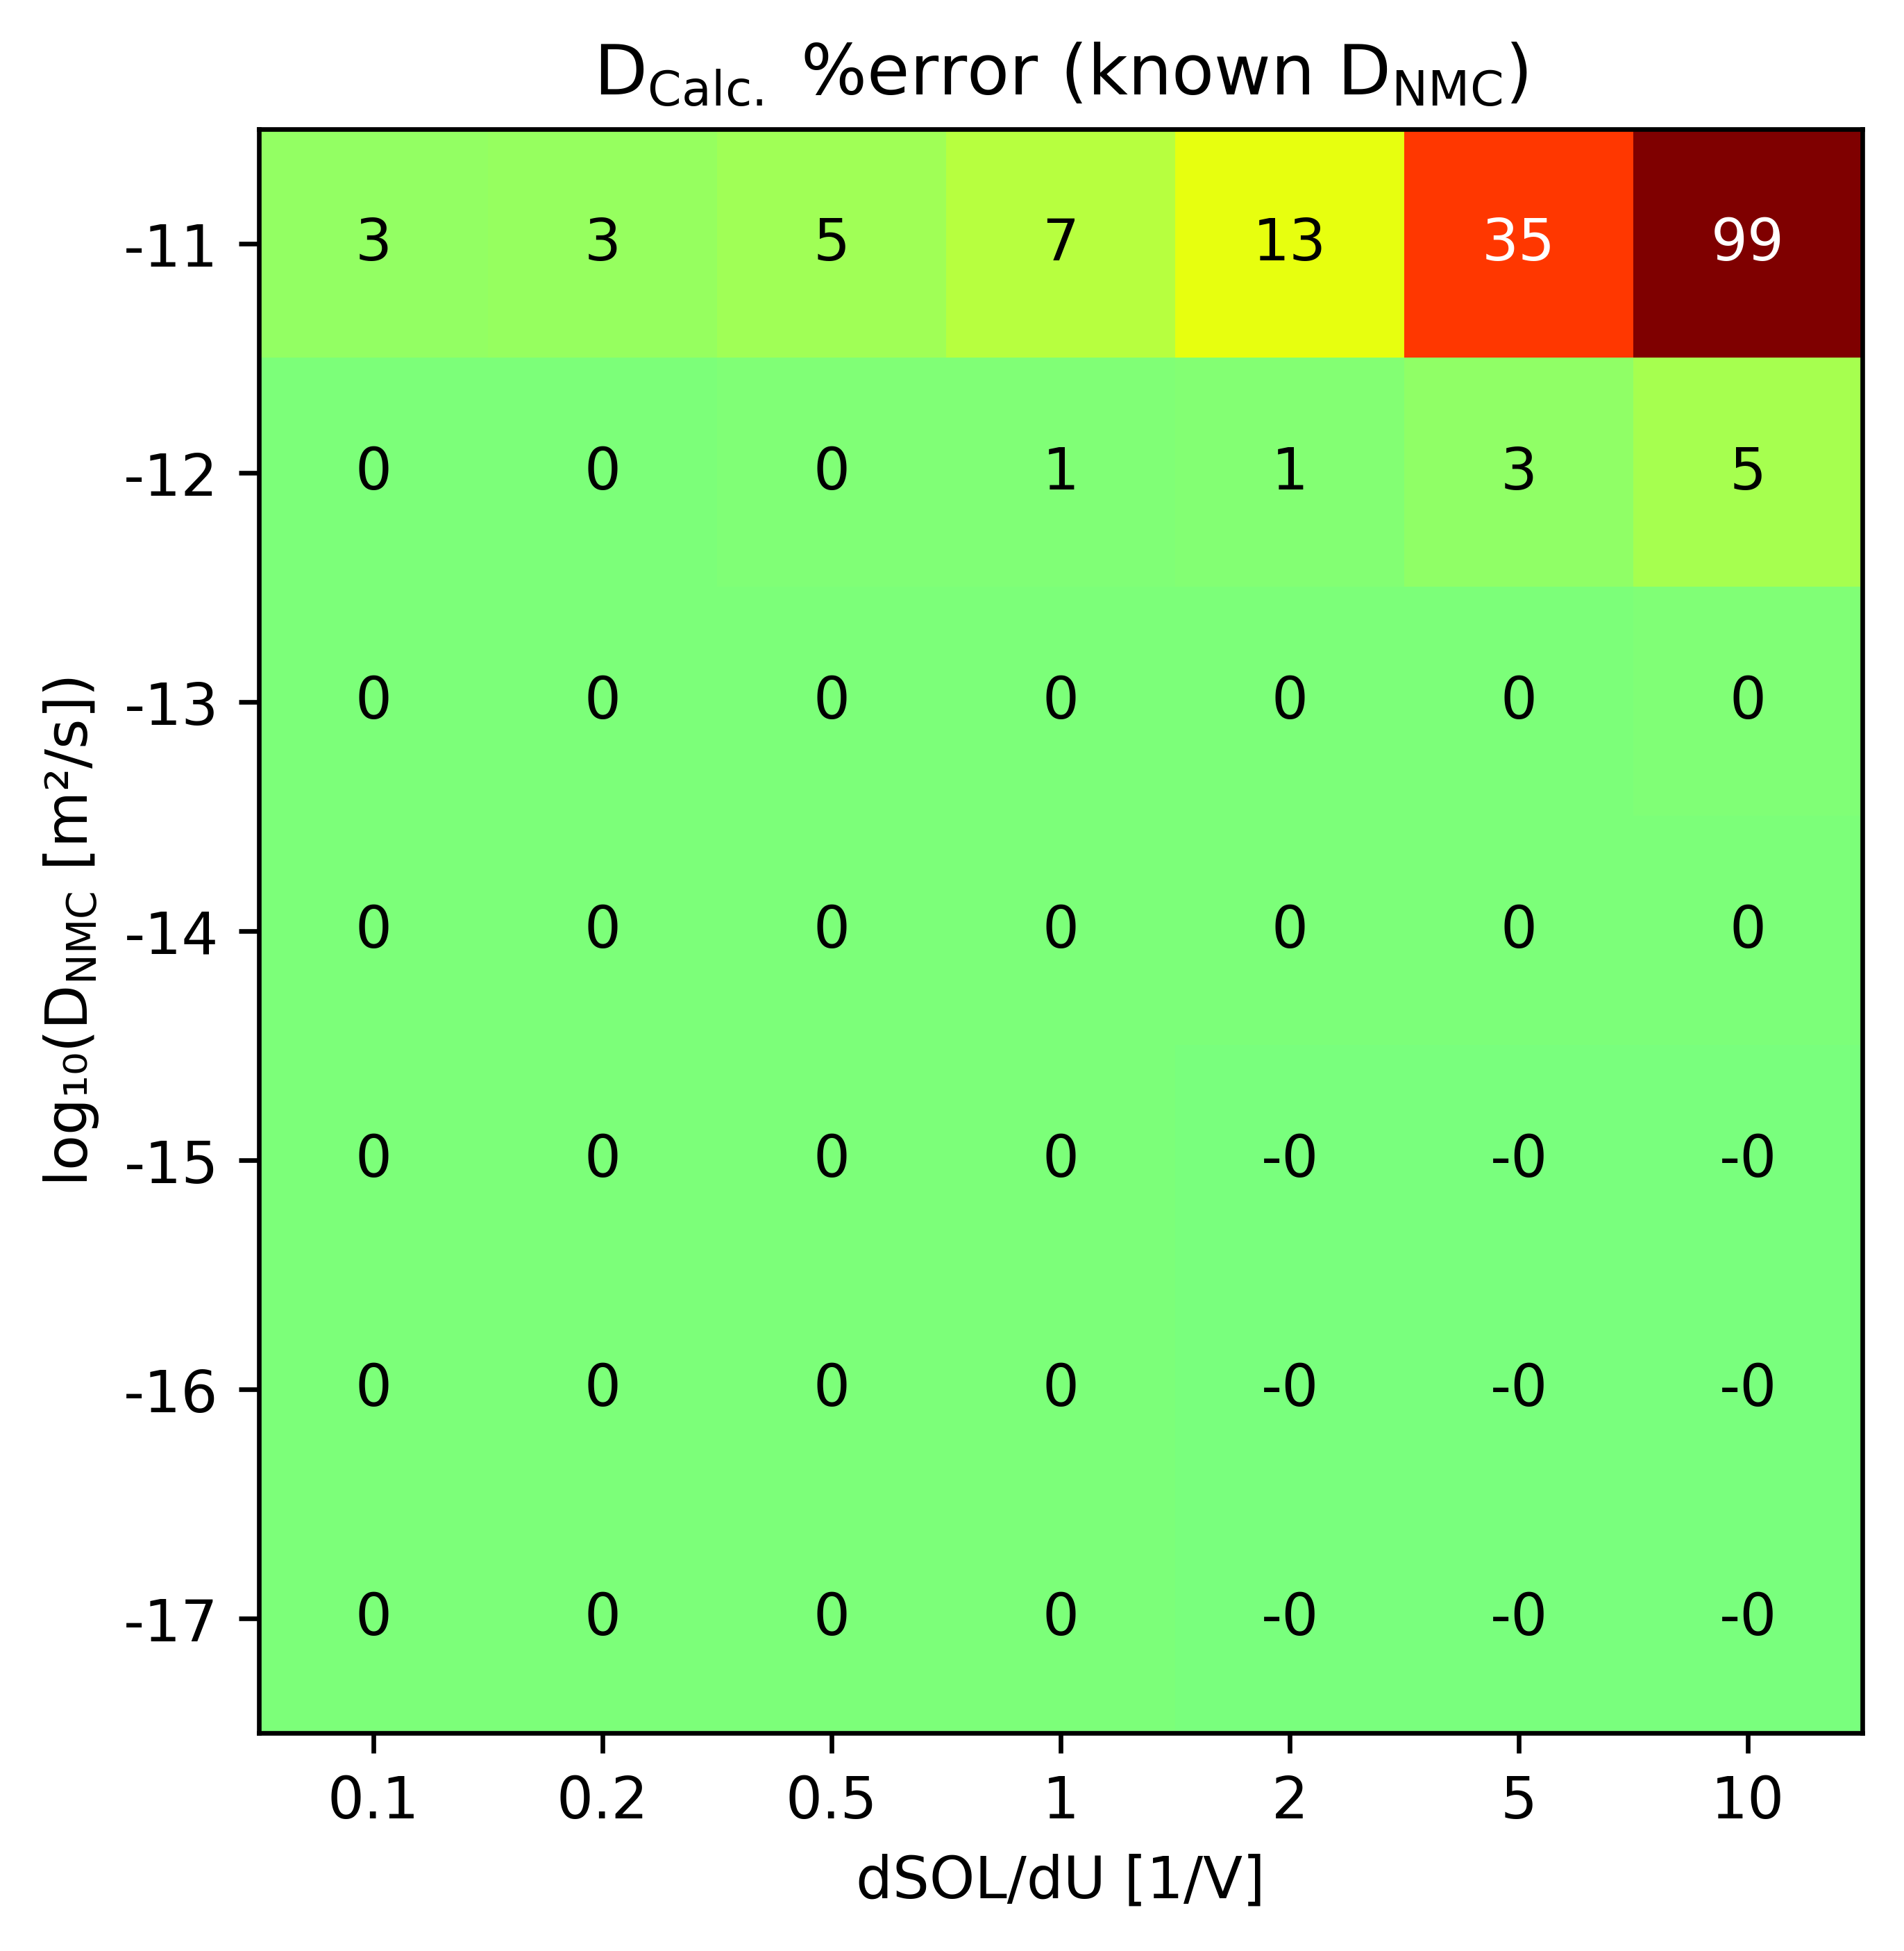

In [ ]:
error_plot("error_map_1",Error_1,"")